In [32]:
import selenium
from selenium import webdriver
from selenium.webdriver.chrome.options import Options
from selenium.webdriver.common.by import By
from selenium.webdriver.common.keys import Keys
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as st
import warnings
warnings.filterwarnings('ignore')

In [ ]:
import selenium
from selenium import webdriver
from selenium.webdriver.chrome.options import Options
from selenium.webdriver.common.by import By
from selenium.webdriver.common.keys import Keys
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


options = Options()
options.add_argument("--start-maximized")

driver = webdriver.Chrome(options=options)

url = "https://www.tatacliq.com/search?text=Kurtas:relevance:list:listId_a0f542f659f04262a77a4b9d0f15713d&icid2=nav:regu:wnav:m1012100:mulb:best:02:R3:clp:bx:010"

driver.get(url)

time.sleep(5)

for i in range(30):

    buttons = driver.find_elements(
        By.XPATH,
        "//*[contains(translate(text(), 'ABCDEFGHIJKLMNOPQRSTUVWXYZ', 'abcdefghijklmnopqrstuvwxyz'), 'show more')]"
    )

    if buttons:
        driver.execute_script("arguments[0].click();", buttons[0])
        time.sleep(3)

        products = driver.find_elements(
            By.CSS_SELECTOR,
            "a.ProductModule__base"
        )

        print("Click", i + 1, "→ Products:", len(products))

    else:
        print("Show More button not found")
        break

data = []

for product in products:

    try:
        brand = product.find_element(
            By.CSS_SELECTOR,
            ".ProductDescription__headerText"
        ).text.strip()
    except:
        brand = None

    try:
        product_name = product.find_element(
            By.CSS_SELECTOR,
            ".ProductDescription__description"
        ).text.strip()
    except:
        product_name = None
        
    try:
        product_link = product.get_attribute("href")
    except:
        product_link = None
        
    try:
        price_elements = product.find_elements(
            By.CSS_SELECTOR,
            ".ProductDescription__boldText"
        )
    
        price = None
    
        for element in price_elements:
            text = element.text.strip()
    
            if "₹" in text:
                price = text.replace("₹", "").strip()
                break
    
    except:
        price = None

    try:
        original_price = product.find_element(
            By.CSS_SELECTOR,
            ".ProductDescription__priceCancelled"
        ).text.strip()
    
        original_price = original_price.replace("₹", "").replace(",", "").strip()
    
    except:
        original_price = None

    try:
        discount = product.find_element(
            By.CSS_SELECTOR,
            ".ProductDescription__newDiscountPercent"
        ).text.strip()
    except:
        discount = None

    try:
        rating = product.find_element(
            By.CSS_SELECTOR,
            ".StarRating__starRatingHigh"
        ).text.strip()
    except:
        rating = None

    try:
        reviews = product.find_element(
            By.CSS_SELECTOR,
            ".StarRating__content"
        ).text.strip()
    except:
        reviews = None

    data.append({
    "Brand": brand,
    "Product": product_name,
    "Product_Link": product_link,
    "Price": price,
    "Original_Price": original_price,
    "Discount": discount,
    "Rating": rating,
    "Reviews": reviews
    })

    

df = pd.DataFrame(data)

In [3]:
df

,Brand,Product,Product_Link,Price,Original_Price,Discount,Rating,Reviews
0,Rangmanch by Pantaloons,Rangmanch By Pantaloons Calypso Coral Embroide...,https://www.tatacliq.com/rangmanch-by-pantaloo...,1699,None,None,None,None
1,Libas,Libas Blue Straight Fit Embroidered Kurta,https://www.tatacliq.com/libas-blue-straight-f...,889,3099,71% off,4.8,(5)
2,Biba,Biba Orange Cotton Straight Fit Kurta,https://www.tatacliq.com/biba-orange-cotton-st...,1599,None,None,None,None
3,Daali,Daali Blue Regular Fit Embroidered Kurta,https://www.tatacliq.com/daali-blue-regular-fi...,1249,2499,50% off,3,(2)
4,Melange by Lifestyle,Melange by Lifestyle Pink Embroidered Viscose ...,https://www.tatacliq.com/melange-by-lifestyle-...,1999,None,None,None,None
...,...,...,...,...,...,...,...,...
1235,Cotton Culture,Cotton Culture Green Cotton Regular Fit Geomet...,https://www.tatacliq.com/cotton-culture-green-...,1199,None,None,None,None
1236,Cotton Culture,Cotton Culture Light Blue Cotton Regular Fit E...,https://www.tatacliq.com/cotton-culture-light-...,1199,None,None,None,None
1237,Rangita,Rangita Maroon Flared Fit Embroidered Kurta,https://www.tatacliq.com/rangita-maroon-flared...,1299,2599,50% off,None,None
1238,Rangita,Rangita Wine Regular Fit Embroidered Kurta,https://www.tatacliq.com/rangita-wine-regular-...,999,1999,50% off,None,None


In [4]:
df.isnull().sum()

Brand               0
Product             0
Product_Link        0
Price               0
Original_Price    378
Discount          378
Rating            996
Reviews           955
dtype: int64

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1240 entries, 0 to 1239
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Brand           1240 non-null   object
 1   Product         1240 non-null   object
 2   Product_Link    1240 non-null   object
 3   Price           1240 non-null   object
 4   Original_Price  862 non-null    object
 5   Discount        862 non-null    object
 6   Rating          244 non-null    object
 7   Reviews         285 non-null    object
dtypes: object(8)
memory usage: 77.6+ KB


In [6]:
df["Price"] = pd.to_numeric(df["Price"], errors="coerce")

df["Original_Price"] = pd.to_numeric(
    df["Original_Price"],
    errors="coerce"
)

df["Discount"] = (
    df["Discount"]
    .astype("string")
    .str.replace("% off", "", regex=False)
)

df["Discount"] = pd.to_numeric(
    df["Discount"],
    errors="coerce"
)

df["Rating"] = pd.to_numeric(
    df["Rating"],
    errors="coerce"
)

df["Reviews"] = (
    df["Reviews"]
    .astype("string")
    .str.replace("(", "", regex=False)
    .str.replace(")", "", regex=False)
)

df["Reviews"] = pd.to_numeric(
    df["Reviews"],
    errors="coerce"
)

In [7]:
df.dtypes

Brand              object
Product            object
Product_Link       object
Price               int64
Original_Price    float64
Discount            Int64
Rating            float64
Reviews             Int64
dtype: object

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.shape

(1240, 8)

In [10]:
#filling null values
df.isnull().sum()

Brand               0
Product             0
Product_Link        0
Price               0
Original_Price    378
Discount          378
Rating            996
Reviews           955
dtype: int64

In [11]:
df["Discount"] = df["Discount"].fillna(0)

In [12]:
df[["Original_Price", "Rating", "Reviews"]].describe()

,Original_Price,Rating,Reviews
count,862.000000,244.000000,285.0
mean,2554.584687,4.302869,3.817544
std,1606.256605,0.668294,7.791407
min,599.000000,2.800000,1.0
25%,1699.000000,3.800000,1.0
50%,2199.000000,4.300000,2.0
75%,2950.000000,5.000000,4.0
max,18475.000000,5.000000,85.0


In [13]:
df["Original_Price"] = df["Original_Price"].fillna(df["Original_Price"].median())
df["Rating"] = df["Rating"].fillna(df["Rating"].median())
df["Reviews"] = df["Reviews"].fillna(df["Reviews"].median())

In [14]:
df.isnull().sum()

Brand             0
Product           0
Product_Link      0
Price             0
Original_Price    0
Discount          0
Rating            0
Reviews           0
dtype: int64

In [19]:
df

,Brand,Product,Product_Link,Price,Original_Price,Discount,Rating,Reviews
0,Rangmanch by Pantaloons,Rangmanch By Pantaloons Calypso Coral Embroide...,https://www.tatacliq.com/rangmanch-by-pantaloo...,1699,2199.0,0,4.3,2
1,Libas,Libas Blue Straight Fit Embroidered Kurta,https://www.tatacliq.com/libas-blue-straight-f...,889,3099.0,71,4.8,5
2,Biba,Biba Orange Cotton Straight Fit Kurta,https://www.tatacliq.com/biba-orange-cotton-st...,1599,2199.0,0,4.3,2
3,Daali,Daali Blue Regular Fit Embroidered Kurta,https://www.tatacliq.com/daali-blue-regular-fi...,1249,2499.0,50,3.0,2
4,Melange by Lifestyle,Melange by Lifestyle Pink Embroidered Viscose ...,https://www.tatacliq.com/melange-by-lifestyle-...,1999,2199.0,0,4.3,2
...,...,...,...,...,...,...,...,...
1235,Cotton Culture,Cotton Culture Green Cotton Regular Fit Geomet...,https://www.tatacliq.com/cotton-culture-green-...,1199,2199.0,0,4.3,2
1236,Cotton Culture,Cotton Culture Light Blue Cotton Regular Fit E...,https://www.tatacliq.com/cotton-culture-light-...,1199,2199.0,0,4.3,2
1237,Rangita,Rangita Maroon Flared Fit Embroidered Kurta,https://www.tatacliq.com/rangita-maroon-flared...,1299,2599.0,50,4.3,2
1238,Rangita,Rangita Wine Regular Fit Embroidered Kurta,https://www.tatacliq.com/rangita-wine-regular-...,999,1999.0,50,4.3,2


## Analysis

In [55]:
df['Brand'].value_counts().head()

Brand
Libas               31
Biba                30
Cotton Culture      30
Soch                29
AARKE RITU KUMAR    29
Name: count, dtype: int64

<Axes: ylabel='Density'>

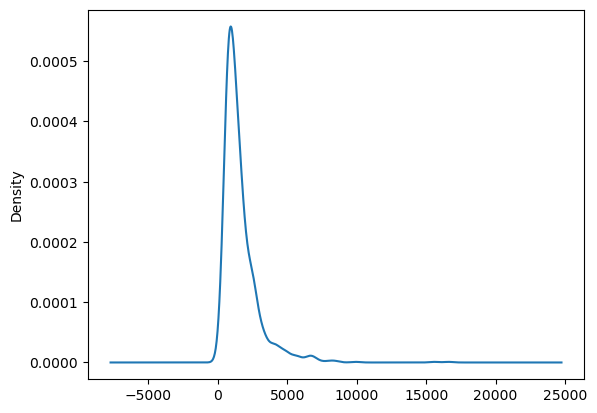

In [17]:
df['Price'].plot(kind = 'kde')

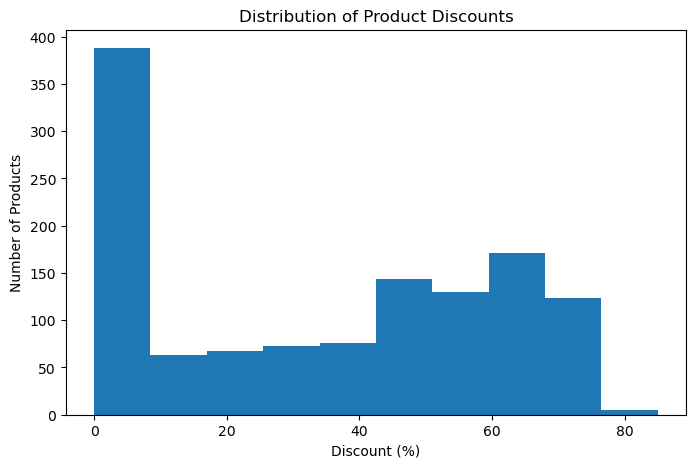

In [21]:
#discount discription
plt.figure(figsize=(8, 5))

df["Discount"].plot(kind="hist", bins=10)

plt.title("Distribution of Product Discounts")
plt.xlabel("Discount (%)")
plt.ylabel("Number of Products")
plt.show()

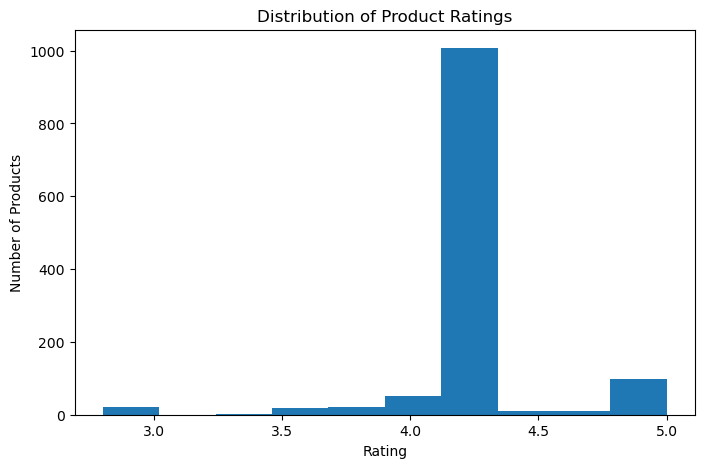

In [31]:
#rating discription
plt.figure(figsize=(8, 5))

df["Rating"].plot(kind="hist", bins=10)

plt.title("Distribution of Product Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Products")
plt.show()

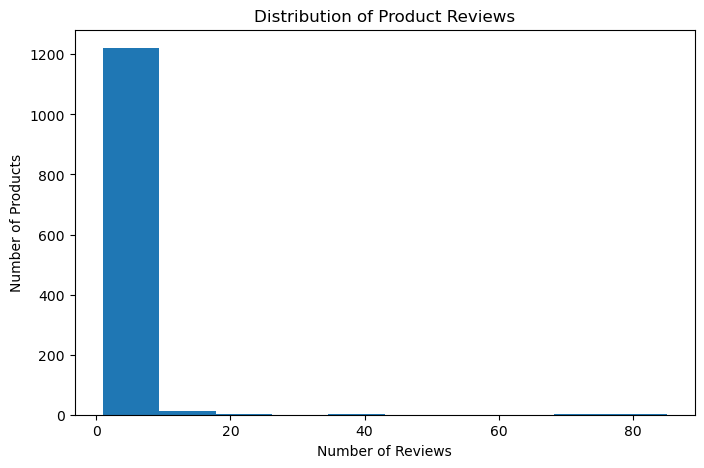

In [25]:
#reviews discription
plt.figure(figsize=(8, 5))

df["Reviews"].plot(kind="hist", bins=10)

plt.title("Distribution of Product Reviews")
plt.xlabel("Number of Reviews")
plt.ylabel("Number of Products")
plt.show()

## Bivariate analysis

In [18]:
df.columns

Index(['Brand', 'Product', 'Product_Link', 'Price', 'Original_Price',
       'Discount', 'Rating', 'Reviews'],
      dtype='object')

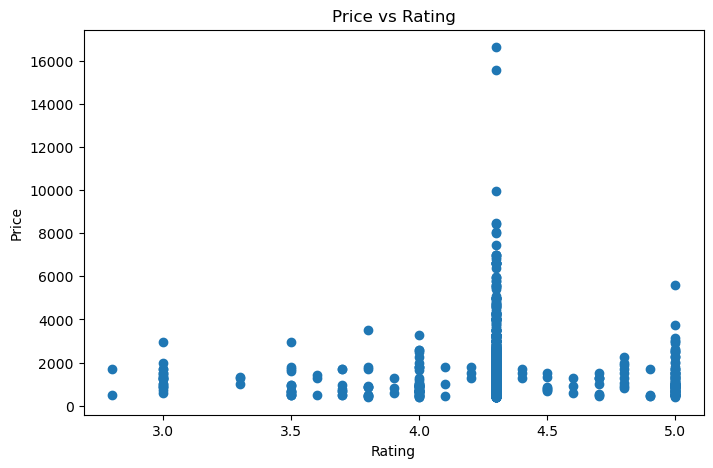

In [57]:
#Price vs Rating
plt.figure(figsize=(8, 5))
plt.scatter(df["Rating"], df["Price"])
plt.title("Price vs Rating")
plt.xlabel("Rating")
plt.ylabel("Price")
plt.show()

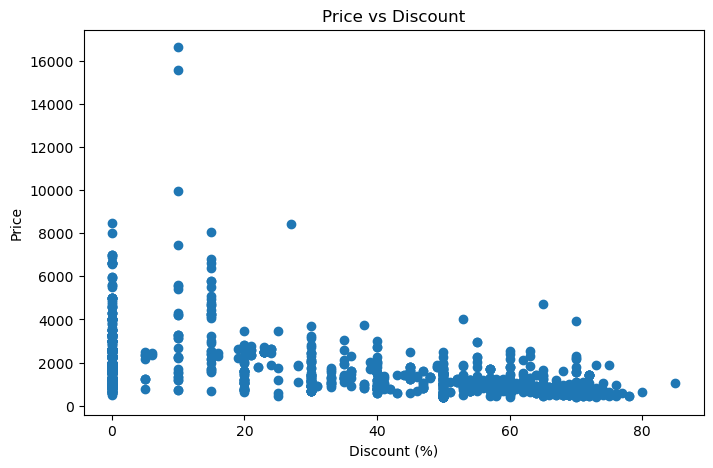

In [56]:
#Price vs Discount
plt.figure(figsize=(8, 5))
plt.scatter(df["Discount"], df["Price"])
plt.title("Price vs Discount")
plt.xlabel("Discount (%)")
plt.ylabel("Price")
plt.show()

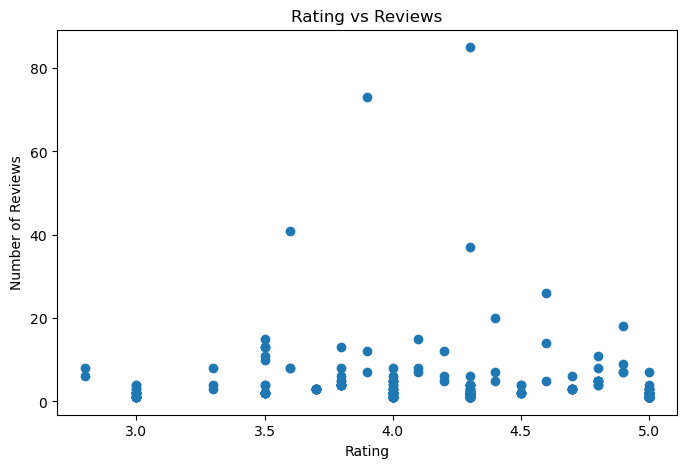

In [59]:
#Rating vs Reviews
plt.figure(figsize=(8, 5))

plt.scatter(df["Rating"], df["Reviews"])

plt.title("Rating vs Reviews")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")

plt.show()

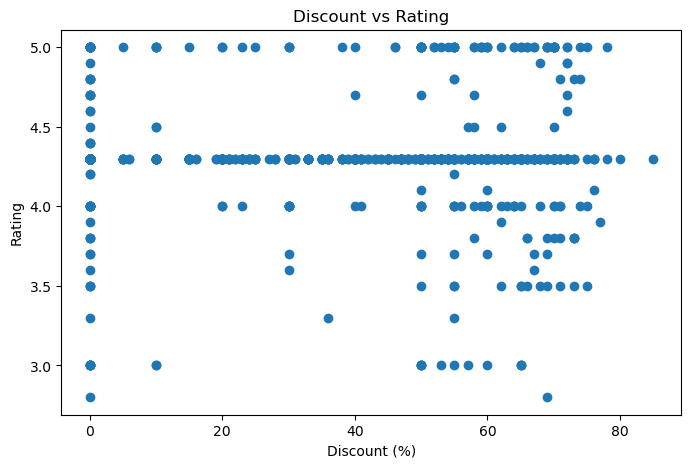

In [58]:
# Discount vs Rating
plt.figure(figsize=(8, 5))
plt.scatter(df["Discount"], df["Rating"])
plt.title("Discount vs Rating")
plt.xlabel("Discount (%)")
plt.ylabel("Rating")
plt.show()

<Figure size 1000x600 with 0 Axes>

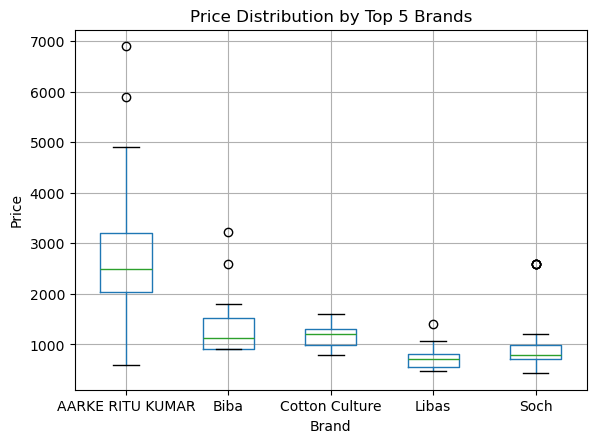

In [60]:
#Top 5 Brands vs Price
top_brands = df["Brand"].value_counts().head(5).index
df_top = df[df["Brand"].isin(top_brands)]

plt.figure(figsize=(10, 6))

df_top.boxplot(column="Price", by="Brand")

plt.title("Price Distribution by Top 5 Brands")
plt.suptitle("")
plt.xlabel("Brand")
plt.ylabel("Price")

plt.show()

## Multi-variate analysis

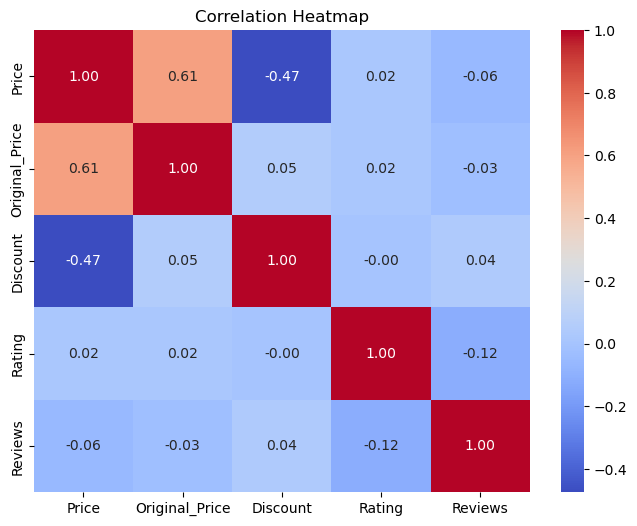

In [30]:
numeric_cols = [
    "Price",
    "Original_Price",
    "Discount",
    "Rating",
    "Reviews"
]

plt.figure(figsize=(8, 6))

sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

### Hypothesis Testing

##### Z-test

In [33]:
def z_stats(sample_mean, pop_std, sample_size, confidence_level):

    area = (1 + confidence_level) / 2
    print(f"Area is {area}")

    z_param = st.norm.ppf(area)
    print(f"Z parameter from the table is {z_param}")

    margin_of_error = z_param * (pop_std / (sample_size ** 0.5))

    lower = sample_mean - margin_of_error
    upper = sample_mean + margin_of_error

    print(f"Confidence interval is ({lower}, {upper})")

    print("Margin of Error:", margin_of_error)

In [34]:
sample_mean = df["Price"].mean()
sample_size = df["Price"].count()

In [35]:
sample_mean

np.float64(1625.3572580645161)

In [36]:
sample_size

np.int64(1240)

In [37]:
pop_std = df["Price"].std(ddof=0)

In [38]:
pop_std

1359.8701766590355

In [39]:
z_stats(
    sample_mean=1625.3572580645161,
    pop_std=1359.8701766590355,
    sample_size=1240,
    confidence_level=0.95
)

Area is 0.975
Z parameter from the table is 1.959963984540054
Confidence interval is (1549.6679216318234, 1701.0465944972088)
Margin of Error: 75.6893364326927


In [40]:
hypothesized_mean = 2000

z_stat = (
    sample_mean - hypothesized_mean
) / (
    pop_std / np.sqrt(sample_size)
)

print("Z-statistic:", z_stat)

Z-statistic: -9.701317462544433


In [41]:
p_value = 2 * (1 - st.norm.cdf(abs(z_stat)))

print("P-value:", p_value)

P-value: 0.0


##### T-test

In [52]:
def t_stats(sample_mean, sample_std, sample_size, confidence_level):

    df = sample_size - 1

    area = (1 + confidence_level) / 2
    print(f"Area is {area}")

    t_param = st.t.ppf(area, df)
    print(f"T parameter from the table is {t_param}")

    margin_of_error = t_param * (sample_std / (sample_size ** 0.5))

    lower = sample_mean - margin_of_error
    upper = sample_mean + margin_of_error

    print(f"Confidence interval is ({lower}, {upper})")

    print("Margin of Error:", margin_of_error)

In [46]:
sample_std = df["Price"].std()

In [47]:
sample_std

1360.4188432848132

In [48]:
t_stat = (
    sample_mean - hypothesized_mean
) / (
    sample_std / np.sqrt(sample_size)
)

print("T-statistic:", t_stat)

T-statistic: -9.697404851995083


In [49]:
df_t = sample_size - 1

print("Degrees of freedom:", df_t)

Degrees of freedom: 1239


In [50]:
p_value = 2 * st.t.sf(abs(t_stat), df_t)

print("P-value:", p_value)

P-value: 1.7538003618867497e-21


In [51]:
alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

Reject the null hypothesis


In [53]:
t_stats(sample_mean, sample_std, sample_size, 0.95)

Area is 0.975
T parameter from the table is 1.961880490546306
Confidence interval is (1549.5633423163472, 1701.151173812685)
Margin of Error: 75.79391574816897


In [54]:
df[["Price", "Original_Price", "Discount", "Rating", "Reviews"]].describe()

,Price,Original_Price,Discount,Rating,Reviews
count,1240.000000,1240.00000,1240.0,1240.000000,1240.0
mean,1625.357258,2446.18871,33.522581,4.300565,2.417742
std,1360.418843,1348.97707,27.000813,0.295964,3.807898
min,389.000000,599.00000,0.0,2.800000,1.0
25%,805.000000,1990.00000,0.0,4.300000,2.0
50%,1242.500000,2199.00000,40.0,4.300000,2.0
75%,1975.000000,2499.00000,58.0,4.300000,2.0
max,16628.000000,18475.00000,85.0,5.000000,85.0


In [61]:
df

,Brand,Product,Product_Link,Price,Original_Price,Discount,Rating,Reviews
0,Rangmanch by Pantaloons,Rangmanch By Pantaloons Calypso Coral Embroide...,https://www.tatacliq.com/rangmanch-by-pantaloo...,1699,2199.0,0,4.3,2
1,Libas,Libas Blue Straight Fit Embroidered Kurta,https://www.tatacliq.com/libas-blue-straight-f...,889,3099.0,71,4.8,5
2,Biba,Biba Orange Cotton Straight Fit Kurta,https://www.tatacliq.com/biba-orange-cotton-st...,1599,2199.0,0,4.3,2
3,Daali,Daali Blue Regular Fit Embroidered Kurta,https://www.tatacliq.com/daali-blue-regular-fi...,1249,2499.0,50,3.0,2
4,Melange by Lifestyle,Melange by Lifestyle Pink Embroidered Viscose ...,https://www.tatacliq.com/melange-by-lifestyle-...,1999,2199.0,0,4.3,2
...,...,...,...,...,...,...,...,...
1235,Cotton Culture,Cotton Culture Green Cotton Regular Fit Geomet...,https://www.tatacliq.com/cotton-culture-green-...,1199,2199.0,0,4.3,2
1236,Cotton Culture,Cotton Culture Light Blue Cotton Regular Fit E...,https://www.tatacliq.com/cotton-culture-light-...,1199,2199.0,0,4.3,2
1237,Rangita,Rangita Maroon Flared Fit Embroidered Kurta,https://www.tatacliq.com/rangita-maroon-flared...,1299,2599.0,50,4.3,2
1238,Rangita,Rangita Wine Regular Fit Embroidered Kurta,https://www.tatacliq.com/rangita-wine-regular-...,999,1999.0,50,4.3,2
